# 07 · Dimensionality reduction

[Guide](../README.md) | [Previous](06_Feature_Selection.ipynb) | [Next](08_Outlier_Handling.ipynb)

Compare four compression choices; keep compression only if it helps.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline

## Continue from the earlier lessons

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |

Only the current choice changes. `clone` copies settings, not fitted knowledge; `step__setting` points to one pipeline setting.

**Incomplete training rows:** `any(axis=1)` finds a row with at least one blank; `~` keeps the opposite rows. Filter `y` too so answers stay aligned.

In [6]:
def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [12]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run steps in order. `passthrough` skips a step. `FunctionSampler` applies a row-changing function only during fitting; every prediction-time row is kept. Balancing also runs only during fitting.

In [13]:
pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("reduce", "passthrough"),
    ("model", LogisticRegression(solver="liblinear", max_iter=1000, random_state=42)),
])

## Compare on the same three splits
Train on two groups, score the third, and rotate. **F1** balances precision and recall;
**accuracy** counts all correct answers; **ROC-AUC** measures probability ranking.
**F1 spread** shows how much scores change across the three splits.

In [14]:
# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

PCA makes weighted mixtures of numerical inputs called **components**.
**Explained variance** means retained input variation—not prediction accuracy.
All compression is fitted inside each training split when scoring.

| Strategy | What it keeps | Benefit / cost |
|---|---|---|
| No PCA | Original selected columns | Most readable; no compression |
| PCA: 95% variation | Mixtures retaining most input variation | Compact; useful predictive detail may have low variation |
| SVD: 2 components | Two mixtures without subtracting column means | Can work on sparse tables; two directions may lose much detail |
| LDA: 1 direction | A label-informed goal/miss separating direction | Uses answers during training; linear assumptions may miss patterns |

**SVD** is singular value decomposition. **LDA** is linear discriminant analysis;
binary classification gives at most one LDA direction. Neither is guaranteed to beat the original inputs.

In [15]:
models = {
    "No PCA": clone(pipeline),
    "PCA: 95% variation": clone(pipeline).set_params(reduce=PCA(n_components=0.95)),
    "SVD: 2 components": clone(pipeline).set_params(reduce=TruncatedSVD(n_components=2, random_state=42)),
    "LDA: 1 direction": clone(pipeline).set_params(reduce=LinearDiscriminantAnalysis(n_components=1)),
}

,method,F1,F1 spread,accuracy,ROC-AUC
0,No PCA,0.880,2.000e-03,0.893,0.960
3,LDA: 1 direction,0.875,9.000e-04,0.888,0.958
1,PCA: 95% variation,0.299,9.100e-03,0.602,0.730
2,SVD: 2 components,0.299,9.100e-03,0.602,0.732


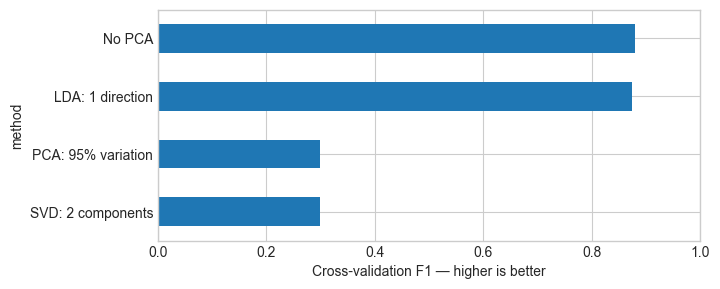

Continue with: No PCA


In [16]:
results = compare(models, X, y)
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [17]:
plot_X, plot_y = X.copy(), y.copy()
plot_X, plot_y = remove_incomplete_rows(plot_X, plot_y)
plot_X = add_features(plot_X)
plot_X = drop_suspected_decoys(plot_X)
encoded = preprocess.fit_transform(plot_X)
encoded_names = preprocess.get_feature_names_out()
plot_selector = clone(pipeline.named_steps["selection"])
encoded = plot_selector.fit_transform(encoded, plot_y)
encoded_names = encoded_names[plot_selector.get_support()]

Before compression: 36 encoded inputs
Two-dimensional picture: 2 mixed coordinates per kick
Components needed for 95% input variation: 2


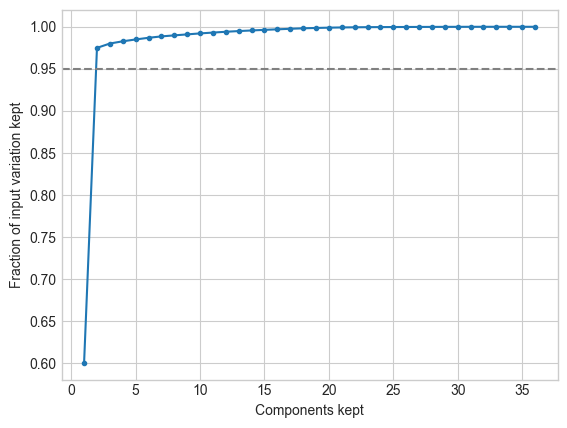

In [18]:
pca = PCA()
points = pca.fit_transform(encoded)
print("Before compression:", encoded.shape[1], "encoded inputs")
print("Two-dimensional picture: 2 mixed coordinates per kick")
components_needed = np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.95) + 1
print("Components needed for 95% input variation:", components_needed)
plt.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker=".")
plt.axhline(0.95, linestyle="--", color="gray")
plt.xlabel("Components kept")
plt.ylabel("Fraction of input variation kept")
plt.show()

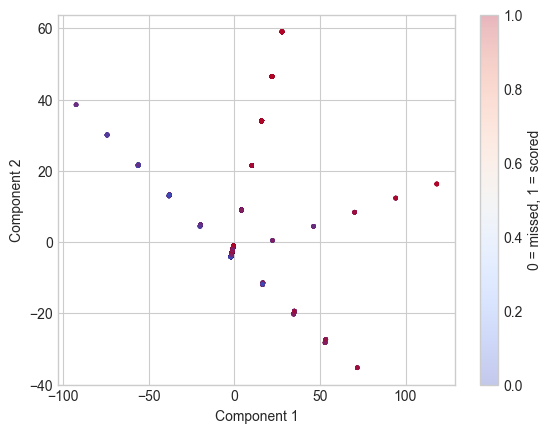

,component 1,component 2
0,-1.772,-3.718
1,-2.003,-4.157
2,-1.585,-3.344
3,-1.695,-3.568
4,-1.687,-3.537


In [19]:
plt.scatter(points[:, 0], points[:, 1], c=plot_y, s=5, alpha=0.3, cmap="coolwarm")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(label="0 = missed, 1 = scored")
plt.show()
display(pd.DataFrame(points[:5, :2], columns=["component 1", "component 2"]))

## Example: what is inside the first component?
The weights below show which encoded inputs contribute most to the mixture; signs give direction.
High retained variation is not the same as retaining goal/miss information.
Robust scaling reduces the influence of typical extremes but does not make every column's variance equal.
Ratios and squared features can still dominate a PCA picture.

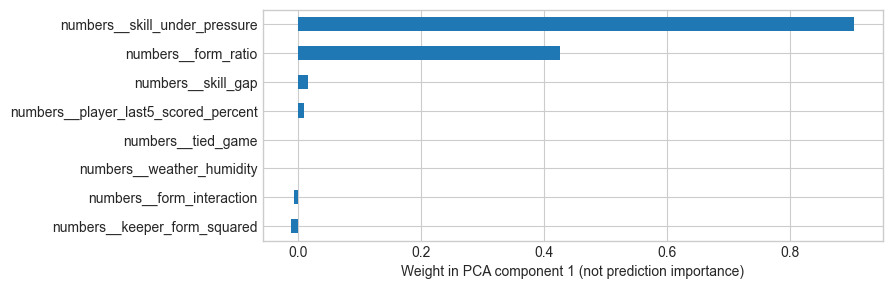

In [20]:
weights = pd.Series(pca.components_[0], index=encoded_names)
largest = weights.abs().nlargest(8).index
weights.loc[largest].sort_values().plot.barh(figsize=(8, 3))
plt.xlabel("Weight in PCA component 1 (not prediction importance)")
plt.show()

**Why the choice?** Large-variation directions need not separate goals from misses.
Keeping original inputs is a valid choice if PCA lowers F1. The full-training fit above is a picture, not an evaluation.

**Other alternatives:** kernel PCA captures nonlinear mixtures (more costly); autoencoders learn a compact
representation with a neural network (more settings). t-SNE and UMAP are exploratory maps,
not automatic classification improvements. The PCA picture above illustrates compression; it does not select the winning method.

## Choice carried into the next lesson

**Reduction: No PCA.** Preserves the original information; large input-variation directions were not a better prediction representation here.

This is the best tested choice at this stage, not proof that a small score gap is significant or that every combination has been tried.